# Level 3: final test evaluation

Evaluate the frozen configuration selected from this level's three-configuration development comparison. Its training duration is the median best validation epoch, fixed before test access. Exact architecture and settings are read from the saved selection and checked against the checkpoint.

Use only saved development-fitted scalers and the development-mean baseline. There is no training, scaler fitting, or checkpoint selection during evaluation. Report map-level and simulation-level RMSE/MAE in original units, ordered `[Omega_m, sigma_8]`.

Select `.venv/bin/python`, restart the kernel after module changes, and run top to bottom. Reruns evaluate the same fixed checkpoint. Test scores are for reporting, not for selecting another configuration. Both levels' selections were frozen before either level's first test evaluation.


## 1. Locate the project and output files

All level-1 evaluation artifacts stay under `mlp/level3/`. Shared evaluation code lives in `mlp/evaluate.py`.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import json

PROJECT_ROOT=next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "mlp" / "data.py").is_file()), None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open the notebook inside the cosmoreg project.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))

import numpy as np
from mlp.final_train import load_final_model
from mlp.evaluate import evaluate_test_model

LEVEL_ROOT=PROJECT_ROOT / "mlp" / "level3"
SPECTRA_ROOT=PROJECT_ROOT / "powerspectrum"
LEVEL=3
selection=json.loads((LEVEL_ROOT/f"level{LEVEL}_final_selection.json").read_text())
assert selection["level"]==LEVEL
name=selection["configuration_name"]
settings=selection["settings"]
CHECKPOINT_PATH=LEVEL_ROOT/"checkpoints"/f"level{LEVEL}_{name}_seed{settings['seed']}_epochs{settings['epochs']}.pt"
RESULTS_PATH=LEVEL_ROOT / "level3_test_results.json"
FIGURE_PATH=LEVEL_ROOT / "level3_test_predictions.png"
print("Checkpoint:",CHECKPOINT_PATH)


Checkpoint: /home/meatpigeon/Personal/classes/csci494/cosmoreg/mlp/level3/checkpoints/level3_larger_seed42_epochs12.pt


## 2. Verify the frozen model's identity before evaluation

Inspect saved settings and record the checkpoint hash. The hash ties the report to the exact saved weights and preprocessing. This cell does not load test arrays.

In [2]:
saved=load_final_model(CHECKPOINT_PATH)
assert saved["settings"]["level"]==LEVEL
for key,value in settings.items():
    assert saved["settings"][key]==value
assert saved["settings"]["configuration_name"]==name
assert saved["settings"]["comparison_sha256"]==selection["comparison_sha256"]
assert saved["training_maps"]==7200
assert len(saved["training_simulation_ids"])==480
checkpoint_hash=sha256(CHECKPOINT_PATH.read_bytes()).hexdigest()
print("Architecture:",[50,*settings["hidden_dims"],2])
print("Configuration:",name)
print("Fixed duration:",settings["epochs"],"epochs")
print("Training simulations:",len(saved["training_simulation_ids"]))
print("Checkpoint SHA-256:",checkpoint_hash)


Architecture: [50, 64, 32, 2]
Configuration: larger
Fixed duration: 12 epochs
Training simulations: 480
Checkpoint SHA-256: ee23b52efa40b07994e2bfe53db454fe91c62f3e7da06038af7d631ded07bc26


## 3. Evaluate the untouched test group

The helper loads only the checkpoint's level-specific test arrays. It checks row counts, finite values, shared targets within simulations, and absence of overlap with saved training simulation IDs. It then applies saved scalers and makes predictions. Assertions verify that model weights and the checkpoint file stay unchanged.

In [3]:
test_results=evaluate_test_model(CHECKPOINT_PATH,SPECTRA_ROOT)
assert test_results["checkpoint_sha256"]==checkpoint_hash
assert test_results["test_maps"]==1800
assert test_results["test_simulations"]==120
assert test_results["simulation_predictions"].shape==(120,2)
_,maps_per_simulation=np.unique(test_results["map_simulation_ids"],return_counts=True)
assert np.all(maps_per_simulation==15)
assert np.all(test_results["simulation_metrics"]["rmse"]<=test_results["map_metrics"]["rmse"]+1e-6)
print("Evaluated",test_results["test_maps"],"maps from",test_results["test_simulations"],"test simulations.")
print("Standardized-target test MSE:",test_results["test_loss"])
print("Standardized-target baseline MSE:",test_results["baseline_loss"])
print("No training or scaler fitting performed.")


Evaluated 1800 maps from 120 test simulations.
Standardized-target test MSE: 0.6408352255821228
Standardized-target baseline MSE: 0.9890347123146057
No training or scaler fitting performed.


## 4. Report errors against the development-mean baseline

```text
RMSE = sqrt(mean((prediction - target)**2))
MAE  = mean(abs(prediction - target))
RMSE reduction (%) = 100 * (1 - MLP_RMSE / baseline_RMSE)
```

Positive reduction means improvement. Inspect both targets and both metrics; RMSE improvement does not necessarily imply MAE improvement. The baseline means come from development training, not test targets.

In [4]:
for group,key in (("Map-level","map_metrics"),("Simulation-level","simulation_metrics")):
    metrics=test_results[key]
    print(f"\n{group} final test results (original units)")
    print("Target     MLP RMSE  Base RMSE  MLP MAE  Base MAE  RMSE reduction")
    for i,target in enumerate(test_results["target_names"]):
        baseline=metrics["baseline_rmse"][i]
        reduction=100*(1-metrics["rmse"][i]/baseline) if baseline>0 else float("nan")
        print(f"{target:9s}  {metrics['rmse'][i]:.4f}    {baseline:.4f}     {metrics['mae'][i]:.4f}   {metrics['baseline_mae'][i]:.4f}    {reduction:7.1f}%")



Map-level final test results (original units)
Target     MLP RMSE  Base RMSE  MLP MAE  Base MAE  RMSE reduction
Omega_m    0.0896    0.1198     0.0720   0.1027       25.2%
sigma_8    0.0973    0.1124     0.0790   0.0978       13.5%

Simulation-level final test results (original units)
Target     MLP RMSE  Base RMSE  MLP MAE  Base MAE  RMSE reduction
Omega_m    0.0809    0.1198     0.0666   0.1027       32.5%
sigma_8    0.0866    0.1124     0.0713   0.0978       23.0%


## 5. Inspect simulation predictions versus true targets

Each circle is one test simulation, after averaging its 15 map predictions. Crosses show the constant development-mean baseline. The diagonal represents perfect prediction. Shared x/y limits make the distances from that line interpretable.

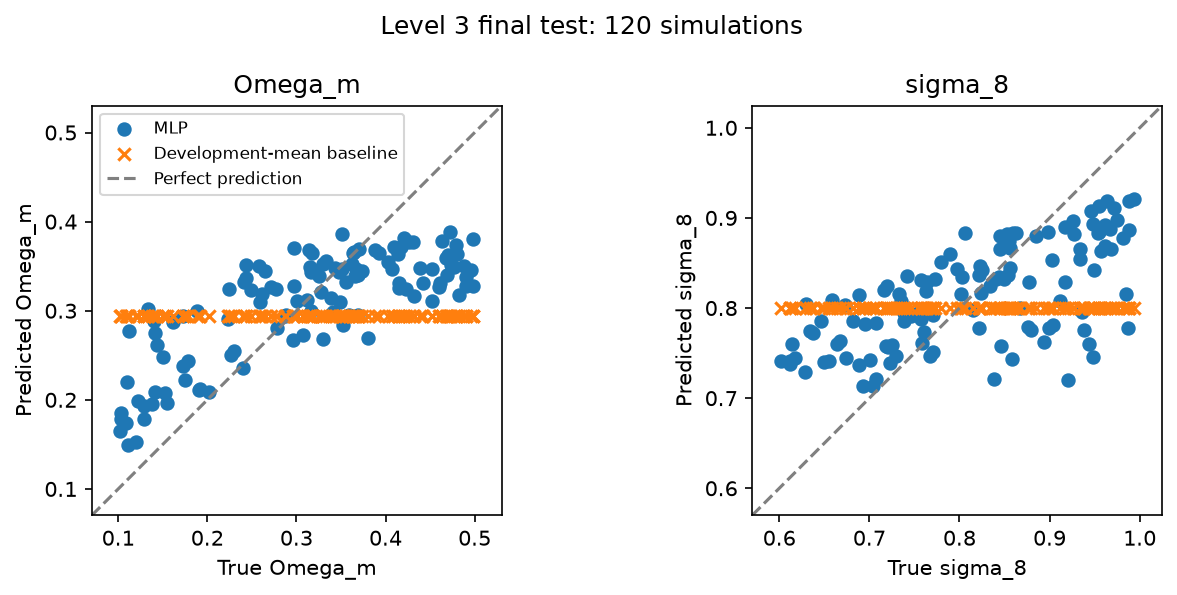

Saved: /home/meatpigeon/Personal/classes/csci494/cosmoreg/mlp/level3/level3_test_predictions.png


In [5]:
import matplotlib.pyplot as plt

fig,axes=plt.subplots(1,2,figsize=(9,4))
for i,(ax,target) in enumerate(zip(axes,test_results["target_names"])):
    truth=test_results["simulation_targets"][:,i]
    prediction=test_results["simulation_predictions"][:,i]
    baseline=np.full_like(truth,test_results["baseline_target_mean"][i])
    values=np.concatenate([truth,prediction,baseline])
    span=float(np.ptp(values))
    margin=0.08*span if span>0 else 0.01
    limits=(float(values.min()-margin),float(values.max()+margin))
    ax.scatter(truth,prediction,label="MLP",s=35)
    ax.scatter(truth,baseline,label="Development-mean baseline",marker="x",s=35)
    ax.plot(limits,limits,linestyle="--",color="gray",label="Perfect prediction")
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal",adjustable="box")
    ax.set_xlabel(f"True {target}")
    ax.set_ylabel(f"Predicted {target}")
    ax.set_title(target)
axes[0].legend(fontsize=8)
fig.suptitle("Level 3 final test: 120 simulations")
fig.tight_layout()
fig.savefig(FIGURE_PATH,dpi=150,bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:",FIGURE_PATH)


## 6. Save the final test report

Record model identity, settings, original-unit predictions and targets, metrics, and the baseline means. Keeping per-simulation predictions makes the reported errors independently checkable. The checkpoint file remains unchanged.

In [6]:
def json_value(value):
    if isinstance(value,np.ndarray):
        return value.tolist()
    if isinstance(value,np.generic):
        return value.item()
    raise TypeError(f"Cannot serialize {type(value).__name__}")

report={
    "evaluation_date":"2026-10-13",
    "checkpoint":str(CHECKPOINT_PATH.relative_to(PROJECT_ROOT)),
    "evaluation_group":"test",
    **test_results,
}
RESULTS_PATH.write_text(json.dumps(report,default=json_value,indent=2,allow_nan=False)+"\n")
assert sha256(CHECKPOINT_PATH.read_bytes()).hexdigest()==checkpoint_hash
print("Saved:",RESULTS_PATH)
print("Final test evaluation complete. Checkpoint unchanged.")


Saved: /home/meatpigeon/Personal/classes/csci494/cosmoreg/mlp/level3/level3_test_results.json
Final test evaluation complete. Checkpoint unchanged.
